## Machine Learning
**Mini-project 03**

Jay Ballesteros

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline
import seaborn as sns
sns.set_style("darkgrid")
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LassoLarsIC 
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold


In [2]:
PATH = ("data")

df_raw = pd.read_csv(os.path.join(PATH, 'Data-Covid003.csv'), encoding="latin-1")

In [3]:
variables = pd.read_excel(os.path.join(PATH, 'PPHA_30545_MP03-Variable_Description.xlsx'))

In [4]:
predictors = variables.loc[
    variables['Source'].isin(['Opportunity Insights', 'PM_COVID']),
    'Variable'
].tolist()

In [5]:
variables

,Count,Variable,Description,Source
0,1,casespc,"COVID-19 Cases per 100,000 Population",NY Times
1,2,deathspc,"COVID-19 Deaths per 100,000 Population",NY Times
2,3,intersects_msa,Urban Area,Opportunity Insights
3,4,cur_smoke_q1,BRFSS: Fraction Current Smokers in Q1,Opportunity Insights
4,5,cur_smoke_q2,BRFSS: Fraction Current Smokers in Q2,Opportunity Insights
...,...,...,...,...
57,58,summer_tmmx,Summer Max Temperature,PM_COVID
58,59,summer_rmax,Summer Max Relative Humidity,PM_COVID
59,60,winter_tmmx,Winter Max Temperature,PM_COVID
60,61,winter_rmax,Winter Max Relative Humidity,PM_COVID


In [6]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3107 entries, 0 to 3106
Data columns (total 93 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   county                   3107 non-null   object 
 1   state                    3107 non-null   object 
 2   fips                     3107 non-null   int64  
 3   cases                    3107 non-null   int64  
 4   deaths                   3107 non-null   int64  
 5   population               3107 non-null   int64  
 6   casespc                  3107 non-null   float64
 7   deathspc                 3107 non-null   float64
 8   cty                      3107 non-null   int64  
 9   county_name              3107 non-null   object 
 10  cty_pop2000              3107 non-null   int64  
 11  cz                       3107 non-null   int64  
 12  cz_name                  3107 non-null   object 
 13  cz_pop2000               3107 non-null   int64  
 14  statename               

# 3. Data Analysis

## 3.1.

The “Variable Description.xlsx” spreadsheet contains a list of variables that we’ll use for our analyses. Note that this is not a full list of all the variables in the dataset, although it’s close (we are ignoring a few perfectly co-linear predictors). Filter the full set of variables in the dataset down to the the Opportunity Insights and PM COVID variables listed in the spreadsheet along with county, state, and deathspc.

In [7]:
df = df_raw[['county', 'state', 'deathspc'] + predictors]

In [8]:
df.shape

(3107, 63)

## 3.2.

Compute and report descriptive (summary) statistics for deathspc and the subset of Opportunity Insights and PM COVID variables you filtered in previous question.

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
deathspc,3107.0,0.751995,1.792700,0.000000,0.000000,0.143666,0.689514,50.773304
intersects_msa,3107.0,0.596717,0.490636,0.000000,0.000000,1.000000,1.000000,1.000000
cur_smoke_q1,3107.0,0.212659,0.149348,0.000000,0.000000,0.250000,0.310931,1.000000
cur_smoke_q2,3107.0,0.171048,0.128130,0.000000,0.000000,0.198718,0.250000,1.000000
cur_smoke_q3,3107.0,0.134467,0.132181,0.000000,0.000000,0.142857,0.200000,1.000000
...,...,...,...,...,...,...,...,...
summer_tmmx,3107.0,303.126997,3.173950,290.455540,300.848035,303.290440,305.817430,313.872680
summer_rmax,3107.0,88.970517,9.689271,31.643282,88.052494,91.320313,94.812389,99.778748
winter_tmmx,3107.0,280.404875,6.597855,264.693820,275.113020,280.154690,285.543750,298.340360
winter_rmax,3107.0,87.469432,4.811207,58.159798,85.093342,88.028793,90.747704,97.672874


## 3.3.

Note that some variables have missing values. This causes problems when estimating the models. Normally we’d impute missing values, but to keep things simple, given the size of our data, you should drop all observations (rows) with missing values.

In [10]:
df = df.dropna()

In [11]:
df.shape

(2915, 63)

In [12]:
df.isna().sum().sum()

np.int64(0)

## 3.4.

Create a separate dummy variable for each of the 48 states and the District of Columbia in the dataset (so you’ll create 49 dummy variables in total, but dropping observations with missing values may reduce this number).

In [13]:
df = pd.get_dummies(df, columns=['state'], drop_first=False, dtype=int)

## 3.5. 

Split the sample into a training set (80%) and a test set (20%). Be sure to set a random state so you can replicate your work. There are odd patterns in the results with some splits of the data, so to avoid confusion and facilitate grading, please set random_state=11.

In [14]:
df.columns.to_list()

['county',
 'deathspc',
 'intersects_msa',
 'cur_smoke_q1',
 'cur_smoke_q2',
 'cur_smoke_q3',
 'cur_smoke_q4',
 'bmi_obese_q1',
 'bmi_obese_q2',
 'bmi_obese_q3',
 'bmi_obese_q4',
 'exercise_any_q1',
 'exercise_any_q2',
 'exercise_any_q3',
 'exercise_any_q4',
 'brfss_mia',
 'puninsured2010',
 'reimb_penroll_adj10',
 'mort_30day_hosp_z',
 'adjmortmeas_amiall30day',
 'adjmortmeas_chfall30day',
 'med_prev_qual_z',
 'primcarevis_10',
 'diab_hemotest_10',
 'diab_eyeexam_10',
 'diab_lipids_10',
 'mammogram_10',
 'cs00_seg_inc',
 'cs00_seg_inc_pov25',
 'cs00_seg_inc_aff75',
 'cs_race_theil_2000',
 'gini99',
 'poor_share',
 'inc_share_1perc',
 'frac_middleclass',
 'scap_ski90pcm',
 'rel_tot',
 'cs_frac_black',
 'cs_frac_hisp',
 'unemp_rate',
 'cs_labforce',
 'cs_elf_ind_man',
 'cs_born_foreign',
 'mig_inflow',
 'mig_outflow',
 'pop_density',
 'frac_traveltime_lt15',
 'hhinc00',
 'median_house_value',
 'ccd_exp_tot',
 'score_r',
 'cs_fam_wkidsinglemom',
 'subcty_exp_pc',
 'taxrate',
 'tax_st_dif

In [15]:
X = df.drop(columns=['deathspc', 'county'])
y = df['deathspc']

In [16]:
X_train, X_test, y_train, y_test = train_test_split(X, y, 
                                                    test_size=0.2,
                                                    random_state=11)

## 3.6.

Using the training set, fit a model of COVID-19 deaths per capita (y=deathspc) as a function of the Opportunity Insights and PM COVID predictors listed in the spreadsheet, as well as state-level fixed effects (the state dummy variables) using OLS.

**(a)** Using the model you fit, calculate and report the MSE in both the training and test sets.

- For the train: MSE of 1.29
- For the test: MSE of 1.83

In [17]:
ols = LinearRegression().fit(X_train, y_train)

In [18]:
y_pred_train = ols.predict(X_train)
mse_train_ols = mean_squared_error(y_train, y_pred_train)
print("OLS-Train MSE: ", round(mse_train_ols,2))

OLS-Train MSE:  1.29


In [19]:
y_pred_test = ols.predict(X_test)
mse_test_ols = mean_squared_error(y_test, y_pred_test)
print("OLS-Test MSE: ", round(mse_test_ols,2))

OLS-Test MSE:  1.83


**(b)** Why might you be concerned about overfitting in this context? Is there any evidence of overfitting? Briefly explain.

The potential evidence of overfitting is the difference between the test and train MSE (~0.54). This difference is represents a potential generalization and suggests that the model might be overfitting. Nonetheless the difference itself does not proves that the entire problem is overfitting; also reflects variation between the samples or characteristics hard to predict. 

## 3.7. 

Use the training set to estimate ridge regression and the lasso analogs to the OLS model in the previous question. For each, you should report a plot of the cross-validation estimates of the test error as a function of the value of the hyperparameter (λ ) that indicates the tuned value of λ.

**(a)** Calculate each model for a grid or range of values of λ . You will want to adjust the values you search over based on what you learn in the subsequent steps, but start by using 101 values of λ from 0.01 to 100.

In [20]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)  
X_test_s = scaler.transform(X_test)       

In [21]:
exponents_ridge = np.linspace(0, 4, 101)
alphas_ridge = 10 ** exponents_ridge

In [22]:
exponents_lasso = np.linspace(-4, 0, 101)
alphas_lasso = 10 ** exponents_lasso

**(b)** Using 10-fold cross-validation (10FCV) (on the training data) to estimate the test error for each model at the given value of λ . Shuffle the data randomly for splitting. Please set random_state=25 when doing so.

In [23]:
folds = KFold(n_splits=10, shuffle=True, random_state=25)

In [24]:
cv_mse_ridge = []
for a in alphas_ridge:
    scores = cross_val_score(Ridge(alpha=a), X_train_s, y_train,
                             cv=folds, scoring='neg_mean_squared_error')
    cv_mse_ridge.append(-scores.mean())

In [25]:
cv_mse_lasso = []
for a in alphas_lasso:
    scores = cross_val_score(Lasso(alpha=a, max_iter=10000), X_train_s, y_train,
                             cv=folds, scoring='neg_mean_squared_error')
    cv_mse_lasso.append(-scores.mean())

**(c)** Plotting the 10FCV estimates of the test error as a function of the value of λ.

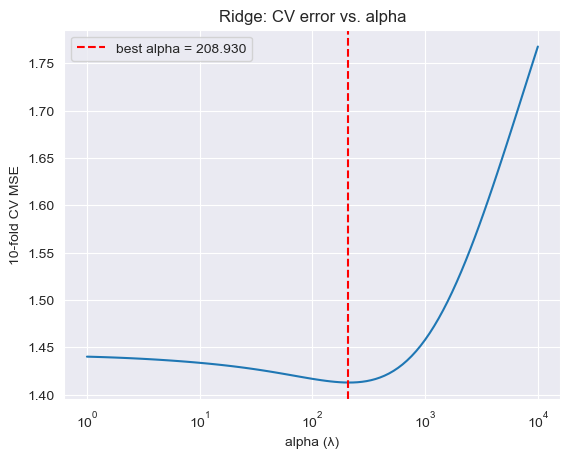

In [26]:
best_alpha_ridge = alphas_ridge[np.argmin(cv_mse_ridge)]  

plt.plot(alphas_ridge, cv_mse_ridge)
plt.xscale('log')
plt.axvline(best_alpha_ridge, linestyle='--', color='red',
            label=f'best alpha = {best_alpha_ridge:.3f}')
plt.xlabel('alpha (λ)')
plt.ylabel('10-fold CV MSE')
plt.title('Ridge: CV error vs. alpha')
plt.legend()
plt.show()

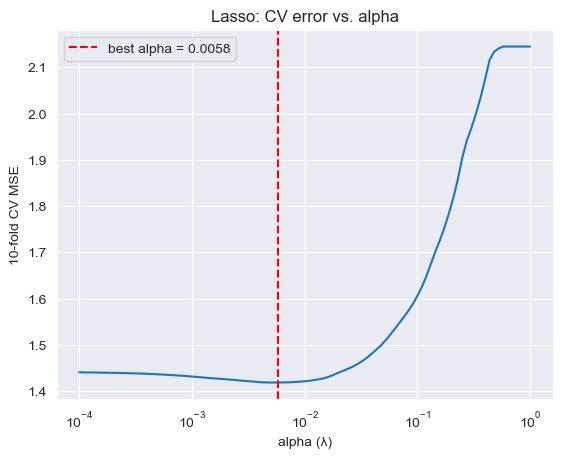

In [27]:
best_alpha_lasso = alphas_lasso[np.argmin(cv_mse_lasso)]  

plt.plot(alphas_lasso, cv_mse_lasso)
plt.xscale('log')
plt.axvline(best_alpha_lasso, linestyle='--', color='red',
            label=f'best alpha = {best_alpha_lasso:.4f}')
plt.xlabel('alpha (λ)')
plt.ylabel('10-fold CV MSE')
plt.title('Lasso: CV error vs. alpha')
plt.legend()
plt.show()

**(d)** Choosing and reporting the optimal value of λ

- Ridge: 208.93
- Lasso: 0.0058

**(e)** Re-estimating your model on the full training set using that optimal value of λ

In [28]:
ridge_best = Ridge(alpha=best_alpha_ridge).fit(X_train_s, y_train)

In [29]:
lasso_best = Lasso(alpha=best_alpha_lasso, max_iter=10000).fit(X_train_s, y_train)

## 3.8.

Using the ridge regression and the lasso models you trained based on the optimal values of λ you found in the previous question, calculate and report the training and test set prediction errors (MSE) for each model. Did ridge regression and/or the lasso improve your prediction over OLS? Which model performs the best? Briefly explain which model you would recommend to the CDC and why.

Test MSE: OLS = 1.8274, Ridge = 1.8209, Lasso = 1.8113.

Both Ridge and Lasso beat OLS on the test set (lower MSE), though OLS had the lowest training MSE. The best model is Lasso, since it has the lowest test MSE and also drops 16 predictors (91 of 107 kept), giving a simpler model. The recommendation is to use Lasso. It predicts best on new data and is easier to interpret with fewer variables.

In [30]:
y_pred_train_ridge = ridge_best.predict(X_train_s) 
mse_train_ridge = mean_squared_error(y_train, y_pred_train_ridge)
print("Ridge-Train MSE: ", round(mse_train_ridge, 4))

Ridge-Train MSE:  1.3002


In [31]:
y_pred_test_ridge = ridge_best.predict(X_test_s)
mse_test_ridge = mean_squared_error(y_test, y_pred_test_ridge)
print("Ridge-Test MSE: ", round(mse_test_ridge, 4))

Ridge-Test MSE:  1.8209


In [32]:
y_pred_train_lasso = lasso_best.predict(X_train_s) 
mse_train_lasso = mean_squared_error(y_train, y_pred_train_lasso)
print("Lasso-Train MSE: ", round(mse_train_lasso, 4))

Lasso-Train MSE:  1.2966


In [33]:
y_pred_test_lasso = lasso_best.predict(X_test_s)
mse_test_lasso = mean_squared_error(y_test, y_pred_test_lasso)
print("Lasso-Test MSE: ", round(mse_test_lasso, 4))

Lasso-Test MSE:  1.8113


In [34]:
mse_table = pd.DataFrame({
    'Train MSE': [mse_train_ols, mse_train_ridge, mse_train_lasso],
    'Test MSE': [mse_test_ols, mse_test_ridge, mse_test_lasso]
}, index=['OLS', 'Ridge', 'Lasso']).round(4)
mse_table

,Train MSE,Test MSE
OLS,1.2867,1.8274
Ridge,1.3002,1.8209
Lasso,1.2966,1.8113


In [35]:
print("Lasso nonzero coefficients:", np.sum(lasso_best.coef_ != 0), "of", len(lasso_best.coef_))

Lasso nonzero coefficients: 91 of 107
